# Gender Classification on CelebA with VGG-16 Transfer Learning

A binary image classifier that predicts CelebA's `Male` attribute from face photos, built in PyTorch on top of an ImageNet-pretrained VGG-16.

**Result:** 97.0% accuracy on a held-out test set of 3,000 images.

### Dataset

[CelebA](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html) is a large-scale face attributes dataset with more than 200K celebrity images, each annotated with 40 binary attributes and covering large pose variations and background clutter. To keep training time manageable, this project uses a **30,000-image subset** (`CelebA30k`) and the `Male` attribute as the label (`-1` = female, `1` = male).

The data is split with stratification on the label:

| Split | Share | Images |
|---|---|---|
| Train | 80% | 24,000 |
| Validation | 10% | 3,000 |
| Test | 10% | 3,000 |

The test set is used only for the final evaluation, not for model selection or tuning.

### Approach

- Load VGG-16 with ImageNet weights and keep its architecture, replacing only the last classifier layer with a single-logit output trained with `BCEWithLogitsLoss`.
- Compare two transfer-learning strategies:
  - **`freeze_all`**: freeze every convolutional layer and train only the classifier head.
  - **`finetune_last_block`**: also unfreeze the last convolutional block (`features[24:]`).
- Train each strategy with learning rates `1e-3` and `1e-4` (Adam, batch size 64, 10 epochs, random horizontal flips).
- Pick the configuration with the lowest validation loss and evaluate it on the test set.

## 1. Setup

In [21]:
import os
import random
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

np.random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


## 2. Load the Data

Put `CelebA30k.csv` and `CelebA30k.zip` in `DATA_DIR`. On Colab they are read from Google Drive; locally, from `./data`.

In [22]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/My Drive/celeba'
    WORK_DIR = '/content/data'
except ImportError:
    DATA_DIR = 'data'
    WORK_DIR = 'data'

csv_path = os.path.join(DATA_DIR, 'CelebA30k.csv')
zip_path = os.path.join(DATA_DIR, 'CelebA30k.zip')
extract_path = os.path.join(WORK_DIR, 'CelebA30k')

if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(WORK_DIR)

df = pd.read_csv(csv_path)
gender_data = df[['filename', 'Male']].copy()


## 3. Explore the Data

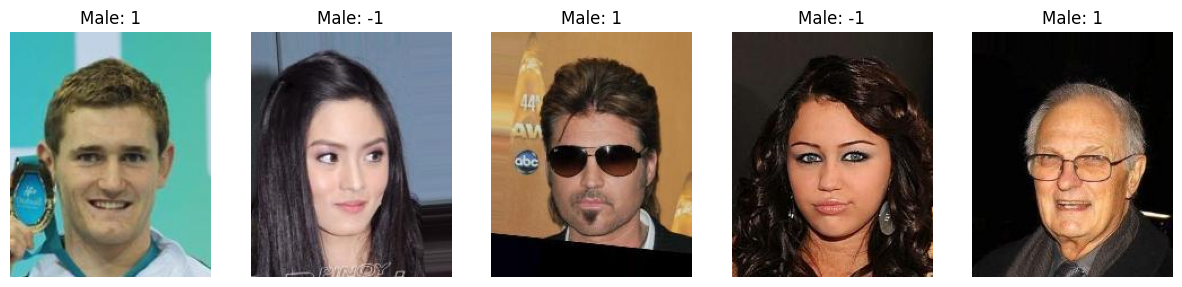

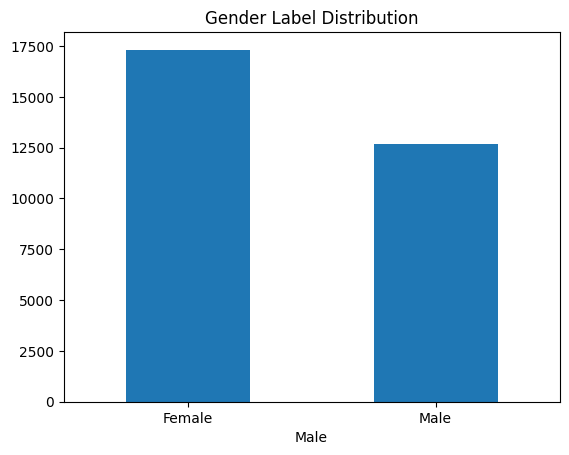

In [27]:
plt.figure(figsize=(15, 5))
for i in range(5):
    idx = random.randint(0, len(gender_data)-1)
    img_path = os.path.join(extract_path, gender_data.loc[idx, 'filename'])
    label = gender_data.loc[idx, 'Male']
    img = Image.open(img_path)
    plt.subplot(1, 5, i+1)
    plt.imshow(img)
    plt.title(f"Male: {label}")
    plt.axis('off')
plt.show()

gender_data['Male'].value_counts().sort_index().plot(kind='bar')
plt.title("Gender Label Distribution")
plt.xticks([0, 1], ["Female", "Male"], rotation=0)
plt.show()



## 4. Train / Validation / Test Split

Stratified 80 / 10 / 10 split so all three sets keep the same gender ratio.

In [30]:
train_df, temp_df = train_test_split(gender_data, test_size=0.2, stratify=gender_data['Male'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['Male'], random_state=42)


## 5. Preprocessing & Data Loaders

Images are resized to 224×224 for VGG-16. Random horizontal flips are applied to the training set only. CelebA labels are mapped from `{-1, 1}` to `{0, 1}`.

In [32]:
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

transform_eval = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

class CelebADataset(Dataset):
    def __init__(self, dataframe, img_dir, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.dataframe.loc[idx, 'filename'])
        image = Image.open(img_path).convert("RGB")
        label = torch.tensor((self.dataframe.loc[idx, 'Male'] + 1) // 2, dtype=torch.float32)
        if self.transform:
            image = self.transform(image)
        return image, label

img_dir = extract_path
train_loader = DataLoader(CelebADataset(train_df, img_dir, transform_train), batch_size=64, shuffle=True)
val_loader = DataLoader(CelebADataset(val_df, img_dir, transform_eval), batch_size=64)
test_loader = DataLoader(CelebADataset(test_df, img_dir, transform_eval), batch_size=64)


## 6. Model: VGG-16 with a Binary Head

The convolutional backbone is frozen. With `finetune_last_block=True`, the last convolutional block (`conv5_1` to `conv5_3`, i.e. `features[24:]`) is unfrozen as well. The final 4096→1000 layer is replaced by a 4096→1 layer.

In [33]:
def build_vgg16_model(finetune_last_block=False):
    model = models.vgg16(weights='IMAGENET1K_V1')
    for param in model.features.parameters():
        param.requires_grad = False
    if finetune_last_block:
        for param in model.features[24:].parameters():
            param.requires_grad = True
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, 1)
    return model.to(device)


## 7. Training Loop

In [34]:
def train_model(model, train_loader, val_loader, lr=1e-4, epochs=10):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    train_loss_values, val_loss_values = [], []

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(X).squeeze()
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        avg_train_loss = train_loss / len(train_loader)
        train_loss_values.append(avg_train_loss)

        model.eval()
        val_loss = 0
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                outputs = model(X).squeeze()
                loss = criterion(outputs, y)
                val_loss += loss.item()
        avg_val_loss = val_loss / len(val_loader)
        val_loss_values.append(avg_val_loss)

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
    return train_loss_values, val_loss_values


## 8. Experiments

Train all four strategy / learning-rate combinations and collect test-set predictions for each.

In [35]:
results = []
configs = [
    {"strategy": "freeze_all", "lr": 1e-3, "fine": False},
    {"strategy": "freeze_all", "lr": 1e-4, "fine": False},
    {"strategy": "finetune_last_block", "lr": 1e-3, "fine": True},
    {"strategy": "finetune_last_block", "lr": 1e-4, "fine": True},
]

for cfg in configs:
    print(f"\nRunning {cfg['strategy']} | LR={cfg['lr']}")
    model = build_vgg16_model(finetune_last_block=cfg['fine'])
    train_loss, val_loss = train_model(model, train_loader, val_loader, lr=cfg['lr'], epochs=10)

    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for X, y in test_loader:
            X = X.to(device)
            outputs = model(X).squeeze()
            preds = torch.round(torch.sigmoid(outputs)).cpu().numpy()
            y_true.extend(y.numpy())
            y_pred.extend(preds)

    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    results.append({
        "strategy": cfg['strategy'],
        "lr": cfg['lr'],
        "train_loss": train_loss,
        "val_loss": val_loss,
        "accuracy": acc,
        "confusion_matrix": cm,
        "y_true": y_true,
        "y_pred": y_pred
    })



Running freeze_all | LR=0.001
Epoch 1/10 | Train Loss: 0.2338 | Val Loss: 0.1807
Epoch 2/10 | Train Loss: 0.1662 | Val Loss: 0.1541
Epoch 3/10 | Train Loss: 0.1336 | Val Loss: 0.1449
Epoch 4/10 | Train Loss: 0.1143 | Val Loss: 0.1530
Epoch 5/10 | Train Loss: 0.1111 | Val Loss: 0.1485
Epoch 6/10 | Train Loss: 0.0981 | Val Loss: 0.1704
Epoch 7/10 | Train Loss: 0.0852 | Val Loss: 0.1560
Epoch 8/10 | Train Loss: 0.0793 | Val Loss: 0.1646
Epoch 9/10 | Train Loss: 0.0676 | Val Loss: 0.2428
Epoch 10/10 | Train Loss: 0.0637 | Val Loss: 0.2590

Running freeze_all | LR=0.0001
Epoch 1/10 | Train Loss: 0.1860 | Val Loss: 0.1456
Epoch 2/10 | Train Loss: 0.1211 | Val Loss: 0.1499
Epoch 3/10 | Train Loss: 0.0889 | Val Loss: 0.1282
Epoch 4/10 | Train Loss: 0.0706 | Val Loss: 0.1501
Epoch 5/10 | Train Loss: 0.0570 | Val Loss: 0.1401
Epoch 6/10 | Train Loss: 0.0414 | Val Loss: 0.1673
Epoch 7/10 | Train Loss: 0.0339 | Val Loss: 0.2250
Epoch 8/10 | Train Loss: 0.0298 | Val Loss: 0.1763
Epoch 9/10 | Train

## 9. Loss Curves & Test Accuracy

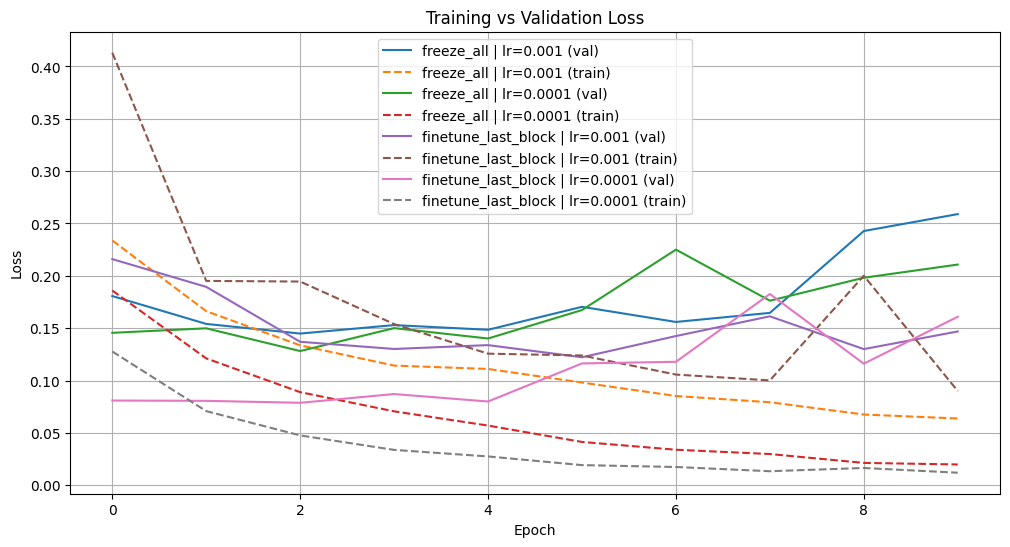


Strategy                  LR         Test Accuracy  
freeze_all                0.001      0.9457         
freeze_all                0.0001     0.9430         
finetune_last_block       0.001      0.9507         
finetune_last_block       0.0001     0.9700         


In [36]:
# Plot training and validation loss
plt.figure(figsize=(12, 6))
for res in results:
    label = f"{res['strategy']} | lr={res['lr']}"
    plt.plot(res['val_loss'], label=f"{label} (val)")
    plt.plot(res['train_loss'], linestyle='dashed', label=f"{label} (train)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Print test accuracy per configuration
print("\n{:<25} {:<10} {:<15}".format("Strategy", "LR", "Test Accuracy"))
for res in results:
    print(f"{res['strategy']:<25} {res['lr']:<10} {res['accuracy']:<15.4f}")


## 10. Best Model Evaluation

The best configuration is chosen by **lowest validation loss**, so the test set stays untouched during model selection.


Best Model: finetune_last_block | LR=0.0001
Classification Report:
              precision    recall  f1-score   support

      Female       0.98      0.97      0.97      1732
        Male       0.95      0.98      0.96      1268

    accuracy                           0.97      3000
   macro avg       0.97      0.97      0.97      3000
weighted avg       0.97      0.97      0.97      3000



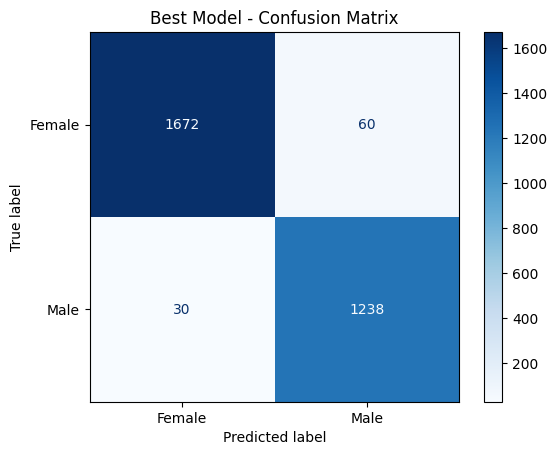

In [37]:
best = min(results, key=lambda r: min(r['val_loss']))
print(f"\nBest Model: {best['strategy']} | LR={best['lr']}")
print("Classification Report:")
print(classification_report(best['y_true'], best['y_pred'], target_names=["Female", "Male"]))

disp = ConfusionMatrixDisplay(confusion_matrix=best['confusion_matrix'], display_labels=["Female", "Male"])
disp.plot(cmap="Blues")
plt.title("Best Model - Confusion Matrix")
plt.grid(False)
plt.show()


## 11. Results

| Strategy | Learning rate | Best val loss | Test accuracy |
|---|---|---|---|
| `freeze_all` | 1e-3 | 0.1449 | 94.57% |
| `freeze_all` | 1e-4 | 0.1282 | 94.30% |
| `finetune_last_block` | 1e-3 | 0.1222 | 95.07% |
| **`finetune_last_block`** | **1e-4** | **0.0787** | **97.00%** |

**Takeaways**

- Unfreezing the last convolutional block with a small learning rate gave both the lowest validation loss and the best test accuracy (97.0%, macro F1 0.97). Adapting the high-level features to faces matters more than tuning only the head.
- At `lr=1e-3`, fine-tuning the conv layers was unstable, with a training-loss spike at epoch 9. The lower rate is much safer when pretrained weights are trainable.
- Every configuration starts to overfit after about 3 to 6 epochs: training loss keeps dropping while validation loss rises.

**Possible improvements**

- Early stopping or checkpointing the best epoch, since validation loss bottoms out well before epoch 10.
- Normalizing with ImageNet mean/std to match the pretrained weights (currently `0.5` per channel).
- Sweeping batch size and number of epochs, and trying stronger augmentation (color jitter, small rotations).